# Assignment 1 bonus: updated motor model

The simple model from Assignment 1 does not fit my motors well, so I add friction and identify the model in three steps:
1. $k_e$ and dry friction from the steps (section 2);
2. $T_m$ and viscous friction on each complex signal, tested on the other two (section 3);
3. RMSE of the simple and the updated model (Table 3, Figure 1).

Data: the Assignment 1 runs (M3 left wheel, M4 right wheel, wheels in the air): steps from −100 to +100 %, a slow chirp, a slow triangle and a square wave + chirp. Each file has `angle,time,PWM`; `battery.txt` has the battery voltage of every run.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize
from scipy.integrate import solve_ivp
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'legend.fontsize': 8, 'figure.constrained_layout.use': True})

if not os.path.isdir('motor_data'):
    from google.colab import files
    os.makedirs('motor_data')
    os.chdir('motor_data')
    files.upload()
    os.chdir('..')

def load(name):                                                           # file columns: angle [deg], time [ms], PWM [%]
    angle, time, pwm = np.loadtxt('motor_data/' + name, delimiter=',', unpack=True)
    return angle * np.pi / 180, time / 1000, pwm                          # SI: rad, s

def speed(theta, t):                                                      # np.gradient, then a moving average of 3 samples
    return pd.Series(np.gradient(theta, t)).rolling(3, center=True, min_periods=1).mean().values

MOTORS = ['M3', 'M4']                                                     # M3 left wheel, M4 right wheel
bat = pd.read_csv('motor_data/battery.txt', names=['file', 'U_before', 'U_after'], index_col='file')   # written by the robot
bat['U'] = (bat.U_before + bat.U_after) / 2                               # battery voltage of each run [V]

Saving battery.txt to battery.txt
Saving chirp_M3.txt to chirp_M3.txt
Saving chirp_M4.txt to chirp_M4.txt
Saving signal_M3.txt to signal_M3.txt
Saving signal_M4.txt to signal_M4.txt
Saving steps_M3.txt to steps_M3.txt
Saving steps_M4.txt to steps_M4.txt
Saving steps_M4_run2.txt to steps_M4_run2.txt
Saving triangle_M3.txt to triangle_M3.txt
Saving triangle_M4.txt to triangle_M4.txt


## 1. Models
**Simple model:** $T_m\dot\omega=U/k_e-\omega$, with $U=\mathrm{PWM}/100\cdot U_{battery}$.

**Updated model:**

$$T_m\dot\omega=\frac{u-U}{k_e}-(|d|+b)\,\omega,\qquad u=d\cdot U_{battery}$$

- $U$: dry friction, $U_{fw}$ forward and $-U_{bw}$ backward. A still wheel starts only when $|u|>U$.
- $b$: viscous friction (grows with speed), $b_{fw}$ and $b_{bw}$.
- $d$: the real PWM duty. TRIK converts the power into the duty with its `motor100` table ([code](https://github.com/trikset/trikRuntime/blob/master/trikControl/src/powerMotor.cpp), [table](https://github.com/trikset/trikRuntime/blob/master/trikControl/configs/kernel-4.14/system-config.xml), [ports](https://github.com/trikset/trikRuntime/blob/master/trikControl/configs/kernel-4.14/model-config.xml)); for example, 60 % power gives only 19 % duty.
- $|d|$ instead of $1$: back-EMF brakes the motor only while the PWM pulse is on (I assume no current between pulses). With $1+b$ the steps give a negative dry friction (section 2).

In [2]:
PWM_PTS, SPEED_PTS = [0, 5, 20, 40, 100], [0, 30, 1700, 2335, 2650]  # trikRuntime 'motor100' table: (duty %, speed)

def duty(power):                                                          # power we set [%] -> real PWM duty [%], as in trikRuntime
    p = np.abs(power)
    d = np.trunc(np.interp(p, np.array(SPEED_PTS) * 100 / SPEED_PTS[-1], PWM_PTS))
    return np.sign(power) * np.where(p >= 100, 100, d)

eps = 0.01                                                                # below this speed the wheel counts as standing still [rad/s]

def motor(state, t, u, d, T_m, k_e, U_fw, U_bw, b_fw, b_bw):             # updated model
    speed, angle = state
    if speed > eps or (abs(speed) <= eps and u > U_fw):                   # turning or starting forward
        U, b = U_fw, b_fw
    elif speed < -eps or (abs(speed) <= eps and u < -U_bw):               # turning or starting backward
        U, b = -U_bw, b_bw
    else:                                                                 # stiction: the wheel stays still
        return [0.0, speed]
    return [-speed * (abs(d) + b) / T_m + (u - U) / (T_m * k_e), speed]

def simple(state, t, u, d, T_m, k_e):                                     # simple model
    speed, angle = state
    return [-speed / T_m + u / (T_m * k_e), speed]

def simulate(name, model, p, real_duty):                                  # solve_ivp, the logged PWM is held until the next sample
    theta, t, pwm = load(name)
    d = (duty(pwm) if real_duty else pwm) / 100
    y, state = np.zeros((len(t), 2)), [0, 0]
    for i in range(1, len(t)):
        rhs = lambda tt, s: model(s, tt, d[i-1] * bat.U[name], d[i-1], *p)
        state = solve_ivp(rhs, t[i-1:i+1], state).y[:, -1]
        y[i] = state
    return y                                                              # y[:,0] speed, y[:,1] angle

print('power -> real duty [%]:', ', '.join(f'{p} -> {duty(p):.0f}' for p in [1, 2, 10, 30, 60, 90, 100]))
print(f'1 % power = {duty(1) / 100 * bat.U.mean():.2f} V on the motor')

power -> real duty [%]: 1 -> 4, 2 -> 5, 10 -> 7, 30 -> 11, 60 -> 19, 90 -> 49, 100 -> 100
1 % power = 0.46 V on the motor


## 2. $k_e$ and dry friction from the steps
Each step is fitted with $\theta(t)=\omega_{ss}(t-T_m+T_me^{-t/T_m})$ to get its steady speed $\omega_{ss}$. At steady speed ($\dot\omega=0$) the updated model gives

$$|u|=U+k_e\,|d|\,|\omega_{ss}|+k_e\,b\,|\omega_{ss}|$$

This is linear, so one least-squares fit over the 20 steps of a motor gives $k_e$, $U_{fw}$, $U_{bw}$ and a first guess of $b$ (section 3 finds the real $b$).

In [3]:
def step_angle(t, w_ss, T_m):                                             # angle of a step response
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

def fit_steps(name):                                                      # w_ss of every PWM block of a step run
    theta, t, pwm = load(name)
    cut = np.r_[0, np.flatnonzero(np.diff(pwm)) + 1, len(pwm)]          # start and end of every constant-PWM block
    w_ss = {}
    for a, b in zip(cut[:-1], cut[1:]):
        if pwm[a] != 0:                                                   # skip motor-off and coasting blocks
            w_ss[pwm[a]] = optimize.curve_fit(step_angle, t[a:b] - t[a], theta[a:b] - theta[a], p0=[8, 0.1],
                                              bounds=([-50, 1e-3], [50, 2]))[0][0]
    return pd.Series(w_ss)

pre = {}
for m in MOTORS:                                                          # steady state: |u| = U + k_e |d| |w| + k_e b |w|
    x = fit_steps(f'steps_{m}.txt')
    d, w, fw = abs(duty(x.index.values)) / 100, abs(x.values), (x.index > 0).astype(float)
    u = d * bat.U[f'steps_{m}.txt']
    k_e, k_e_b, U_fw, U_bw = np.linalg.lstsq(np.c_[d * w, w, fw, 1 - fw], u, rcond=None)[0]
    pre[m] = [k_e, U_fw, U_bw, k_e_b / k_e]                               # k_e, U_fw, U_bw, first guess of b
    U_1b = [np.polyfit(w[fw == s], u[fw == s], 1)[1] for s in (1, 0)]     # same fit with (1 + b) instead of (|d| + b)
    print(f'{m}: with (1 + b) the dry friction would be {U_1b[0]:.2f} V forward, {U_1b[1]:.2f} V backward')
pd.DataFrame(pre, index=['k_e [V s/rad]', 'U_fw [V]', 'U_bw [V]', 'b (first guess)']).T.round(3)

M3: with (1 + b) the dry friction would be -4.62 V forward, -4.91 V backward
M4: with (1 + b) the dry friction would be -4.02 V forward, -4.05 V backward


,k_e [V s/rad],U_fw [V],U_bw [V],b (first guess)
M3,0.700,0.478,0.476,0.031
M4,0.725,0.420,0.547,0.051


**Table 1.** Dry friction is 0.48 V on M3 and 0.42 / 0.55 V (forward / backward) on M4, close to the 0.46 V that 1 % power gives. With $1+b$ instead of $|d|+b$ the dry friction comes out negative (printed above), which is impossible.

## 3. $T_m$ and viscous friction on the complex signals
With $k_e$ and $U$ from Table 1 fixed, `identify()` fits $T_m$, $b_{fw}$, $b_{bw}$ to the measured speed of one complex signal, and the simple model gets its $T_m$ and $k_e$ from the same signal. Both models are then tested on the other two signals. The model speed is smoothed the same way as the measured speed. This cell takes a few minutes.

In [4]:
SIGNALS = {'chirp': 'slow chirp', 'triangle': 'slow triangle', 'signal': 'square+chirp'}
rmse = lambda y, yh: np.sqrt(np.mean((y - yh) ** 2))

def identify(name, model, real, params, x0, bounds, step):                # least squares on the speed of one signal
    theta, t, pwm = load(name)
    err = lambda q: speed(simulate(name, model, params(q), real)[:, 1], t) - speed(theta, t)   # model speed smoothed like the data
    r = optimize.least_squares(err, x0, bounds=bounds, diff_step=step)
    cov = np.linalg.inv(r.jac.T @ r.jac)
    return params(r.x), cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))   # parameters, correlation matrix

def test(name, model, p, real):                                           # RMSE of speed and angle on one signal
    theta, t, pwm = load(name)
    y = simulate(name, model, p, real)
    return rmse(speed(theta, t), speed(y[:, 1], t)), rmse(theta - theta[0], y[:, 1])

models, par, rows = {}, {}, []                                            # takes a few minutes
for m in MOTORS:
    k_e, U_fw, U_bw, b = pre[m]
    for s in SIGNALS:                                                     # identify on s ...
        name = f'{s}_{m}.txt'
        upd, corr = identify(name, motor, True, lambda q: [q[0], k_e, U_fw, U_bw, q[1], q[2]], [0.05, b, b],
                             ([0.005, 0, 0], [1, 3, 3]), [0.005, 0.02, 0.02])
        smp = identify(name, simple, False, list, [0.15, 0.7], ([0.005, 0.05], [2, 10]), [0.005, 0.02])[0]
        models[m, s] = smp, upd
        par[m, SIGNALS[s]] = [upd[0], upd[4], upd[5], abs(corr[0, 1:]).max(), *smp]
        for s2 in SIGNALS:                                                # ... and test on the other two
            if s2 != s:
                (w_s, a_s), (w_u, a_u) = test(f'{s2}_{m}.txt', simple, smp, False), test(f'{s2}_{m}.txt', motor, upd, True)
                rows.append([m, SIGNALS[s], SIGNALS[s2], w_s, w_u, a_s, a_u])
res = pd.DataFrame(rows, columns=['motor', 'identified on', 'tested on', 'speed: simple', 'speed: updated',
                                  'angle: simple', 'angle: updated'])
for m in MOTORS:
    mean = res[res.motor == m].groupby('identified on', sort=False)['speed: updated'].mean()
    print(f'{m}: mean test speed RMSE of the updated model:', ', '.join(f'{k} {v:.2f}' for k, v in mean.items()))
display(pd.DataFrame(par, index=['T_m [s]', 'b_fw', 'b_bw', 'corr(T_m, b)', 'simple: T_m [s]', 'simple: k_e']).T.round(3))
res.set_index(['motor', 'identified on', 'tested on']).round(2)

M3: mean test speed RMSE of the updated model: slow chirp 0.61, slow triangle 0.87, square+chirp 1.07
M4: mean test speed RMSE of the updated model: slow chirp 0.65, slow triangle 0.90, square+chirp 0.94


T_m [s]   b_fw   b_bw  corr(T_m, b)  simple: T_m [s]  \
M3 slow chirp       0.037  0.042  0.038         0.024            0.167   
   slow triangle    0.039  0.030  0.028         0.027            0.438   
   square+chirp     0.037  0.046  0.059         0.068            0.133   
M4 slow chirp       0.034  0.064  0.045         0.072            0.138   
   slow triangle    0.040  0.059  0.036         0.034            0.350   
   square+chirp     0.031  0.080  0.076         0.066            0.102   

                  simple: k_e  
M3 slow chirp           0.583  
   slow triangle        0.454  
   square+chirp         0.686  
M4 slow chirp           0.658  
   slow triangle        0.533  
   square+chirp         0.780

speed: simple  speed: updated  \
motor identified on tested on                                      
M3    slow chirp    slow triangle           2.10            0.57   
                    square+chirp            1.05            0.66   
      slow triangle slow chirp              2.62            1.02   
                    square+chirp            2.62            0.73   
      square+chirp  slow chirp              1.40            1.04   
                    slow triangle           2.79            1.09   
M4    slow chirp    slow triangle           1.58            0.45   
                    square+chirp            1.26            0.85   
      slow triangle slow chirp              2.29            0.78   
                    square+chirp            2.63            1.03   
      square+chirp  slow chirp              1.18            0.81   
                    slow triangle           2.23            1.07   

                                   angle: simple  angle: updated  
motor identified on tested on                                     
M3    slow chirp    slow triangle          21.21            8.04  
                    square+chirp            0.87            1.35  
      slow triangle slow chirp              4.47            2.18  
                    square+chirp            1.10            0.96  
      square+chirp  slow chirp              1.56            3.90  
                    slow triangle          30.20            8.80  
M4    slow chirp    slow triangle          19.46            5.43  
                    square+chirp            2.27            0.53  
      slow triangle slow chirp              1.31            1.45  
                    square+chirp            1.25            0.68  
      square+chirp  slow chirp              5.39            3.00  
                    slow triangle          27.70           11.60

**Table 2** (parameters from each signal) and **Table 3** (RMSE on the other two signals; speed in rad/s, angle in rad).
- The updated model gives about the same $T_m$ (0.031 to 0.040 s) on every signal, and $T_m$ and $b$ are almost uncorrelated (at most 0.072). The simple model's $T_m$ jumps from 0.102 to 0.438 s.
- Speed RMSE: the updated model is lower in all 12 tests (0.45 to 1.09 rad/s, simple 1.05 to 2.79 rad/s). Angle RMSE: lower in 9 of 12.
- The slow chirp is the best signal for identification (mean test speed RMSE 0.61 and 0.65 rad/s).

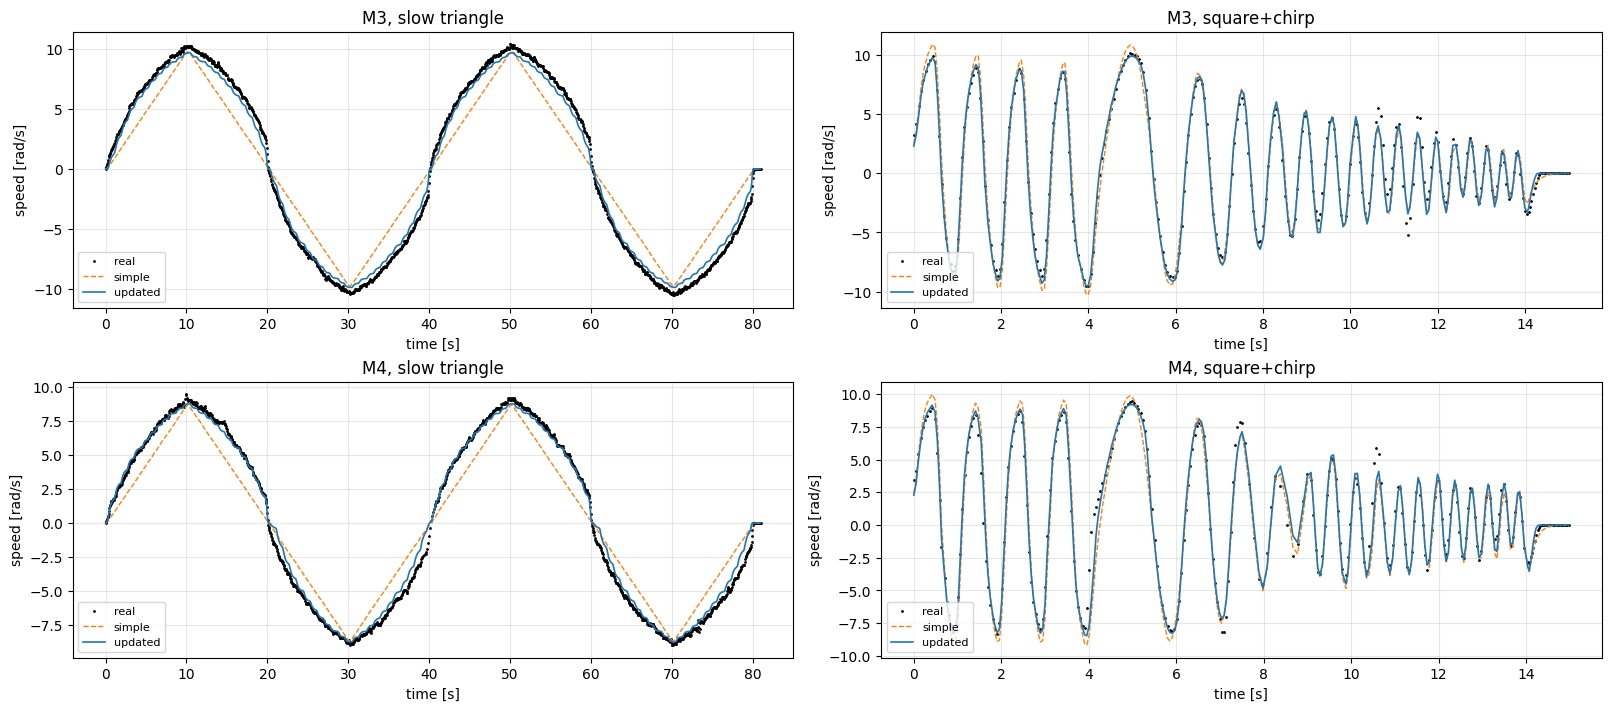

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(16, 7))
for i, m in enumerate(MOTORS):
    smp, upd = models[m, 'chirp']                                         # both models identified on the slow chirp
    for j, s in enumerate(['triangle', 'signal']):                        # the two test signals
        name = f'{s}_{m}.txt'
        theta, t, pwm = load(name)
        ax = axs[i, j]
        ax.plot(t - t[0], speed(theta, t), 'k.', ms=2, label='real')
        ax.plot(t - t[0], speed(simulate(name, simple, smp, False)[:, 1], t), '--', color='tab:orange', lw=1, label='simple')
        ax.plot(t - t[0], speed(simulate(name, motor, upd, True)[:, 1], t), color='tab:blue', lw=1.2, label='updated')
        ax.set(title=f'{m}, {SIGNALS[s]}', xlabel='time [s]', ylabel='speed [rad/s]')
        ax.legend(loc='lower left')
plt.show()

**Figure 1.** Speed on the two test signals, both models identified on the slow chirp. On the triangle the simple model is a straight line, while the real wheel and the updated model jump near zero and bend at high speed (real duty and dry friction). On the square wave + chirp both are close.

**Result:** on the test signals the updated model has a speed RMSE of 0.45 to 0.85 rad/s, against 1.05 to 2.10 rad/s for the simple model identified on the same chirp.